In [4]:
%load_ext autoreload
%autoreload 2

import requests
import pandas as pd
from gasp import weather_cpc

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
import requests
from gasp.weather_cpc import parse_cpc_daily

# 1. Download a sample NOAA text file (e.g., 2011 Population Heating data)
url = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
response = requests.get(url, timeout=30)
text = response.text

# 2. Run your parser function
df = parse_cpc_daily(text)

# 3. Inspect the results
print("Success! DataFrame shape:", df.shape)
display(df.head())

Success! DataFrame shape: (0, 5)


,date,region,measure,weighting,value


In [6]:
import requests
from gasp.weather_cpc import parse_cpc_daily

# 1. Download a sample NOAA text file (e.g., 2011 Population Heating data)
url = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
response = requests.get(url, timeout=30)
text = response.text

# 2. Run your parser function
df = parse_cpc_daily(text)

# 3. Inspect the results
print("Success! DataFrame shape:", df.shape)
display(df.head())

Success! DataFrame shape: (0, 5)


,date,region,measure,weighting,value


In [7]:
import requests
import io
import pandas as pd

# 1. Download the file text
url = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
text = requests.get(url, timeout=30).text
lines = text.strip().splitlines()

# 2. Find where the header/date row is
header_end_idx = 0
for idx, line in enumerate(lines):
    if line.lstrip().startswith(("YYYYMMDD", "Date")):
        header_end_idx = idx
        print(f"Found header at index: {idx}")
        print(f"Header line: {line}")
        break

# 3. Test reading the table text into pandas
data_text = "\n".join(lines[header_end_idx:])
df_test = pd.read_csv(io.StringIO(data_text), sep=r"\s+")

print("\nDataFrame shape:", df_test.shape)
display(df_test.head())


DataFrame shape: (13, 5)


,Product:,Daily,Heating,Degree,Days
0,Regions:,Regions::CensusDivisions,NaN,NaN,NaN
1,Weights:,Population,NaN,NaN,NaN
2,Region|20110101|20110102|20110103|20110104|201...,NaN,NaN,NaN,NaN
3,1|24|23|34|38|38|42|42|39|37|39|43|40|40|48|49...,NaN,NaN,NaN,NaN
4,2|25|25|36|35|37|42|40|44|41|41|43|42|42|46|44...,NaN,NaN,NaN,NaN


In [8]:
import requests
import io
import pandas as pd

# 1. Download the file text
url = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
text = requests.get(url, timeout=30).text
lines = text.strip().splitlines()

# 2. Find where the header/date row is
header_end_idx = 0
for idx, line in enumerate(lines):
    if line.lstrip().startswith(("YYYYMMDD", "Date")):
        header_end_idx = idx
        print(f"Found header at index: {idx}")
        print(f"Header line: {line}")
        break

# 3. Test reading the table text into pandas
data_text = "\n".join(lines[header_end_idx:])
df_test = pd.read_csv(io.StringIO(data_text), sep=r"\s+")

print("\nDataFrame shape:", df_test.shape)
display(df_test.head())


DataFrame shape: (13, 5)


,Product:,Daily,Heating,Degree,Days
0,Regions:,Regions::CensusDivisions,NaN,NaN,NaN
1,Weights:,Population,NaN,NaN,NaN
2,Region|20110101|20110102|20110103|20110104|201...,NaN,NaN,NaN,NaN
3,1|24|23|34|38|38|42|42|39|37|39|43|40|40|48|49...,NaN,NaN,NaN,NaN
4,2|25|25|36|35|37|42|40|44|41|41|43|42|42|46|44...,NaN,NaN,NaN,NaN


In [9]:
import importlib
import gasp.weather_cpc
importlib.reload(gasp.weather_cpc)
from gasp.weather_cpc import parse_cpc_daily

In [10]:
import requests
import io
import pandas as pd

# 1. Download the file text
url = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
text = requests.get(url, timeout=30).text
lines = text.strip().splitlines()

# 2. Find where the header/date row is
header_end_idx = 0
for idx, line in enumerate(lines):
    if line.lstrip().startswith(("YYYYMMDD", "Date")):
        header_end_idx = idx
        print(f"Found header at index: {idx}")
        print(f"Header line: {line}")
        break

# 3. Test reading the table text into pandas
data_text = "\n".join(lines[header_end_idx:])
df_test = pd.read_csv(io.StringIO(data_text), sep=r"\s+")

print("\nDataFrame shape:", df_test.shape)
display(df_test.head())


DataFrame shape: (13, 5)


,Product:,Daily,Heating,Degree,Days
0,Regions:,Regions::CensusDivisions,NaN,NaN,NaN
1,Weights:,Population,NaN,NaN,NaN
2,Region|20110101|20110102|20110103|20110104|201...,NaN,NaN,NaN,NaN
3,1|24|23|34|38|38|42|42|39|37|39|43|40|40|48|49...,NaN,NaN,NaN,NaN
4,2|25|25|36|35|37|42|40|44|41|41|43|42|42|46|44...,NaN,NaN,NaN,NaN


In [11]:
df = parse_cpc_daily(text)
print("Columns found:", df.columns.tolist())


Columns found: ['date', 'region', 'measure', 'weighting', 'value']


In [12]:
import requests
import importlib
import gasp.weather_cpc

# Force reload so Python picks up your saved changes from the .py file
importlib.reload(gasp.weather_cpc)
from gasp.weather_cpc import parse_cpc_daily

# Download a sample NOAA text file
url = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
text = requests.get(url, timeout=30).text

# Run your parser function
df = parse_cpc_daily(text)

# Inspect the final tidy DataFrame
print("Success! DataFrame shape:", df.shape)
display(df.head(10))

Success! DataFrame shape: (3650, 5)


,date,region,measure,weighting,value
0,20110101,1,Daily Heating Degree Days,Population,24
1,20110101,2,Daily Heating Degree Days,Population,25
2,20110101,3,Daily Heating Degree Days,Population,26
3,20110101,4,Daily Heating Degree Days,Population,51
4,20110101,5,Daily Heating Degree Days,Population,12
5,20110101,6,Daily Heating Degree Days,Population,11
6,20110101,7,Daily Heating Degree Days,Population,18
7,20110101,8,Daily Heating Degree Days,Population,47
8,20110101,9,Daily Heating Degree Days,Population,27
9,20110101,CONUS,Daily Heating Degree Days,Population,25


In [13]:
import requests
import importlib
import gasp.weather_cpc

# Force reload so Python picks up your saved changes from the .py file
importlib.reload(gasp.weather_cpc)
from gasp.weather_cpc import parse_cpc_daily

# Download a sample NOAA text file
url = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
text = requests.get(url, timeout=30).text

# Run your parser function
df = parse_cpc_daily(text)

# Inspect the final tidy DataFrame
print("Success! DataFrame shape:", df.shape)
display(df.head(10))

Success! DataFrame shape: (3650, 5)


,date,region,measure,weighting,value
0,2011-01-01,1,Daily Heating Degree Days,Population,24
1,2011-01-01,2,Daily Heating Degree Days,Population,25
2,2011-01-01,3,Daily Heating Degree Days,Population,26
3,2011-01-01,4,Daily Heating Degree Days,Population,51
4,2011-01-01,5,Daily Heating Degree Days,Population,12
5,2011-01-01,6,Daily Heating Degree Days,Population,11
6,2011-01-01,7,Daily Heating Degree Days,Population,18
7,2011-01-01,8,Daily Heating Degree Days,Population,47
8,2011-01-01,9,Daily Heating Degree Days,Population,27
9,2011-01-01,CONUS,Daily Heating Degree Days,Population,25


In [14]:
import requests
from gasp.weather_cpc import parse_cpc_daily

url_2011 = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
df_2011 = parse_cpc_daily(requests.get(url_2011, timeout=30).text)

# Check row count / days per region (should be 365)
print("Days per region in 2011:")
print(df_2011.groupby("region")["date"].count())

# Check specific dates for CONUS/US region
conus_jan1 = df_2011[(df_2011["date"] == "2011-01-01") & (df_2011["region"].str.upper() == "CONUS")]
conus_dec31 = df_2011[(df_2011["date"] == "2011-12-31") & (df_2011["region"].str.upper() == "CONUS")]

print("\nCONUS 2011-01-01 value:", conus_jan1["value"].values)
print("CONUS 2011-12-31 value:", conus_dec31["value"].values)

Days per region in 2011:
region
1        365
2        365
3        365
4        365
5        365
6        365
7        365
8        365
9        365
CONUS    365
Name: date, dtype: int64

CONUS 2011-01-01 value: [25]
CONUS 2011-12-31 value: [18]


In [1]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span to verify continuity
df_multi = fetch_cpc_daily("Population.Heating.txt", 2011, 2015)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))


NameError: name 'datetime' is not defined

In [2]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span to verify continuity
df_multi = fetch_cpc_daily("Population.Heating.txt", 2011, 2015)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))


NameError: name 'datetime' is not defined

In [3]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span to verify continuity
df_multi = fetch_cpc_daily("Population.Heating.txt", 2011, 2015)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))

NameError: name 'datetime' is not defined

In [4]:
%load_ext autoreload
%autoreload 2

In [5]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span to verify continuity
df_multi = fetch_cpc_daily("Population.Heating.txt", 2011, 2015)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))

NameError: name 'datetime' is not defined

In [1]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span to verify continuity
df_multi = fetch_cpc_daily("Population.Heating.txt", 2011, 2015)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))

ParserError: Error tokenizing data. C error: Expected 1 fields in line 3, saw 366


In [1]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span to verify continuity
df_multi = fetch_cpc_daily("Population.Heating.txt", 2011, 2015)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))

ParserError: Expected 1 fields in line 3, saw 366

In [1]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span to verify continuity
df_multi = fetch_cpc_daily("Population.Heating.txt", 2011, 2015)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))

ParserError: Expected 1 fields in line 3, saw 366

In [2]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span to verify continuity
df_multi = fetch_cpc_daily("Population.Heating.txt", 2011, 2015)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))

ParserError: Expected 1 fields in line 3, saw 366

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import inspect
from gasp.weather_cpc import parse_cpc_daily

# This will print the exact source code Python currently has loaded for the function
print(inspect.getsource(parse_cpc_daily))

def parse_cpc_daily(text: str) -> pd.DataFrame:
    lines = text.strip().splitlines()
    
    raw_measure = "unknown"
    raw_weighting = "unknown"
    header_end_idx = 0
    
    # 1. Extract metadata and locate the exact "Region|" header row
    for idx, line in enumerate(lines):
        if line.startswith("Product:"):
            val = line.split(":", 1)[1].strip().lower()
            raw_measure = "hdd" if "heating" in val else "cdd" if "cooling" in val else val
        elif line.startswith("Weights:"):
            raw_weighting = line.split(":", 1)[1].strip().lower()
        elif line.startswith("Region|") or line.lstrip().startswith("Region|"):
            header_end_idx = idx
            break
            
    # Fallback if "Region|" wasn't caught directly
    if header_end_idx == 0:
        pipe_counts = [line.count('|') for line in lines]
        if max(pipe_counts) > 0:
            header_end_idx = max(range(len(pipe_counts)), key=pipe_counts.__getitem__)
            
    # 

In [5]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span (now successfully handling historical files like 1981!)
df_multi = fetch_cpc_daily("Population.Heating.txt", 1981, 1985)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))
print(df_multi.head())

ParserError: Expected 1 fields in line 3, saw 366

In [1]:
from gasp.weather_cpc import fetch_cpc_daily

# Fetch a multi-year span (now successfully handling historical files like 1981!)
df_multi = fetch_cpc_daily("Population.Heating.txt", 1981, 1985)

# Check date continuity across year boundaries
print("Min date:", df_multi["date"].min())
print("Max date:", df_multi["date"].max())
print("Total rows:", len(df_multi))
print(df_multi.head())

Min date: 1981-01-01 00:00:00
Max date: 1985-12-31 00:00:00
Total rows: 18260
        date region measure   weighting  value
0 1981-01-01      1     hdd  population     51
1 1981-01-01      2     hdd  population     45
2 1981-01-01      3     hdd  population     36
3 1981-01-01      4     hdd  population     33
4 1981-01-01      5     hdd  population     24


In [4]:
# Verifies uniqueness across the full composite key required by Contract #4
full_dups = df_multi.duplicated(subset=["date", "region", "measure", "weighting"]).sum()
print("Composite duplicates:", full_dups)  # Should be 0

Composite duplicates: 0


In [1]:
from gasp.weather_cpc import fetch_cpc_daily
from gasp.weather_cpc import parse_cpc_daily
df_2011 = fetch_cpc_daily("Population.Heating.txt", 2011, 2011)

print("Days per region:", df_2011.groupby("region")["date"].nunique().unique()) # Expect [365]

us_2011 = df_2011[df_2011["region"] == "US"].set_index("date")["value"]
print("2011-01-01 US HDD:", us_2011.loc["2011-01-01"])
print("2011-12-31 US HDD:", us_2011.loc["2011-12-31"])

ValueError: Could not locate 'Region|' header row in CPC file.

In [2]:
%load_ext autoreload
%autoreload 2

from gasp.weather_cpc import fetch_cpc_daily, parse_cpc_daily

In [ ]:
df_2011 = fetch_cpc_daily("Population.Heating.txt", 2011, 2011)

print("Days per region:", df_2011.groupby("region")["date"].nunique().unique()) # Expect [365]

us_2011 = df_2011[df_2011["region"] == "US"].set_index("date")["value"]
print("2011-01-01 US HDD:", us_2011.loc["2011-01-01"])
print("2011-12-31 US HDD:", us_2011.loc["2011-12-31"])

ValueError: Could not locate 'Region|' header row in CPC file.

In [1]:
%load_ext autoreload
%autoreload 2

from gasp.weather_cpc import fetch_cpc_daily, parse_cpc_daily

In [2]:
df_2011 = fetch_cpc_daily("Population.Heating.txt", 2011, 2011)

print("Days per region:", df_2011.groupby("region")["date"].nunique().unique()) # Expect [365]

us_2011 = df_2011[df_2011["region"] == "US"].set_index("date")["value"]
print("2011-01-01 US HDD:", us_2011.loc["2011-01-01"])
print("2011-12-31 US HDD:", us_2011.loc["2011-12-31"])

ValueError: Could not locate 'Region|' header row in CPC file.

In [1]:
%load_ext autoreload
%autoreload 2

from gasp.weather_cpc import fetch_cpc_daily, parse_cpc_daily

In [2]:
df_2011 = fetch_cpc_daily("Population.Heating.txt", 2011, 2011)

print("Days per region:", df_2011.groupby("region")["date"].nunique().unique()) # Expect [365]

us_2011 = df_2011[df_2011["region"] == "US"].set_index("date")["value"]
print("2011-01-01 US HDD:", us_2011.loc["2011-01-01"])
print("2011-12-31 US HDD:", us_2011.loc["2011-12-31"])

check these ['Product: Daily Heating Degree Days', 'Regions: Regions::CensusDivisions', 'Weights: Population', 'Region|20110101|20110102|20110103|20110104|20110105|20110106|20110107|20110108|20110109|20110110|20110111|20110112|20110113|20110114|20110115|20110116|20110117|20110118|20110119|20110120|20110121|20110122|20110123|20110124|20110125|20110126|20110127|20110128|20110129|20110130|20110131|20110201|20110202|20110203|20110204|20110205|20110206|20110207|20110208|20110209|20110210|20110211|20110212|20110213|20110214|20110215|20110216|20110217|20110218|20110219|20110220|20110221|20110222|20110223|20110224|20110225|20110226|20110227|20110228|20110301|20110302|20110303|20110304|20110305|20110306|20110307|20110308|20110309|20110310|20110311|20110312|20110313|20110314|20110315|20110316|20110317|20110318|20110319|20110320|20110321|20110322|20110323|20110324|20110325|20110326|20110327|20110328|20110329|20110330|20110331|20110401|20110402|20110403|20110404|20110405|20110406|20110407|20110408

ValueError: Could not locate 'Region|' header row in CPC file.

In [3]:
import requests

url = "https://ftp.cpc.ncep.noaa.gov/htdocs/degree_days/weighted/daily_data/2011/Population.Heating.txt"
response = requests.get(url)

for i, line in enumerate(response.text.splitlines()[:10]):
    print(f"Line {i}: {repr(line)}")

Line 0: 'Product: Daily Heating Degree Days'
Line 1: 'Regions: Regions::CensusDivisions'
Line 2: 'Weights: Population'
Line 3: 'Region|20110101|20110102|20110103|20110104|20110105|20110106|20110107|20110108|20110109|20110110|20110111|20110112|20110113|20110114|20110115|20110116|20110117|20110118|20110119|20110120|20110121|20110122|20110123|20110124|20110125|20110126|20110127|20110128|20110129|20110130|20110131|20110201|20110202|20110203|20110204|20110205|20110206|20110207|20110208|20110209|20110210|20110211|20110212|20110213|20110214|20110215|20110216|20110217|20110218|20110219|20110220|20110221|20110222|20110223|20110224|20110225|20110226|20110227|20110228|20110301|20110302|20110303|20110304|20110305|20110306|20110307|20110308|20110309|20110310|20110311|20110312|20110313|20110314|20110315|20110316|20110317|20110318|20110319|20110320|20110321|20110322|20110323|20110324|20110325|20110326|20110327|20110328|20110329|20110330|20110331|20110401|20110402|20110403|20110404|20110405|20110406|2

In [4]:
import importlib
import gasp.weather_cpc
importlib.reload(gasp.weather_cpc)

from gasp.weather_cpc import fetch_cpc_daily
df_2011 = fetch_cpc_daily("Population.Heating.txt", 2011, 2011)
print(df_2011.head())

check these ['Product: Daily Heating Degree Days', 'Regions: Regions::CensusDivisions', 'Weights: Population', 'Region|20110101|20110102|20110103|20110104|20110105|20110106|20110107|20110108|20110109|20110110|20110111|20110112|20110113|20110114|20110115|20110116|20110117|20110118|20110119|20110120|20110121|20110122|20110123|20110124|20110125|20110126|20110127|20110128|20110129|20110130|20110131|20110201|20110202|20110203|20110204|20110205|20110206|20110207|20110208|20110209|20110210|20110211|20110212|20110213|20110214|20110215|20110216|20110217|20110218|20110219|20110220|20110221|20110222|20110223|20110224|20110225|20110226|20110227|20110228|20110301|20110302|20110303|20110304|20110305|20110306|20110307|20110308|20110309|20110310|20110311|20110312|20110313|20110314|20110315|20110316|20110317|20110318|20110319|20110320|20110321|20110322|20110323|20110324|20110325|20110326|20110327|20110328|20110329|20110330|20110331|20110401|20110402|20110403|20110404|20110405|20110406|20110407|20110408

ValueError: Could not locate 'Region|' header row in CPC file.

In [ ]:
import importlib
import gasp.weather_cpc
importlib.reload(gasp.weather_cpc)

from gasp.weather_cpc import fetch_cpc_daily
df_2011 = fetch_cpc_daily("Population.Heating.txt", 2011, 2011)
print(df_2011.head())

SyntaxError: invalid syntax (574746941.py, line 7)

In [2]:
import importlib
import gasp.weather_cpc
importlib.reload(gasp.weather_cpc)

from gasp.weather_cpc import fetch_cpc_daily
df_2011 = fetch_cpc_daily("Population.Heating.txt", 2011, 2011)
print(df_2011.head())

check these ['Product: Daily Heating Degree Days', 'Regions: Regions::CensusDivisions', 'Weights: Population', 'Region|20110101|20110102|20110103|20110104|20110105|20110106|20110107|20110108|20110109|20110110|20110111|20110112|20110113|20110114|20110115|20110116|20110117|20110118|20110119|20110120|20110121|20110122|20110123|20110124|20110125|20110126|20110127|20110128|20110129|20110130|20110131|20110201|20110202|20110203|20110204|20110205|20110206|20110207|20110208|20110209|20110210|20110211|20110212|20110213|20110214|20110215|20110216|20110217|20110218|20110219|20110220|20110221|20110222|20110223|20110224|20110225|20110226|20110227|20110228|20110301|20110302|20110303|20110304|20110305|20110306|20110307|20110308|20110309|20110310|20110311|20110312|20110313|20110314|20110315|20110316|20110317|20110318|20110319|20110320|20110321|20110322|20110323|20110324|20110325|20110326|20110327|20110328|20110329|20110330|20110331|20110401|20110402|20110403|20110404|20110405|20110406|20110407|20110408

In [3]:
df_2011 = fetch_cpc_daily("Population.Heating.txt", 2011, 2011)
print("Days per region:", df_2011.groupby("region")["date"].nunique().unique())
us_2011 = df_2011[df_2011["region"] == "US"].set_index("date")["value"]
print("2011-01-01 US HDD:", us_2011.loc["2011-01-01"])
print("2011-12-31 US HDD:", us_2011.loc["2011-12-31"])

check these ['Product: Daily Heating Degree Days', 'Regions: Regions::CensusDivisions', 'Weights: Population', 'Region|20110101|20110102|20110103|20110104|20110105|20110106|20110107|20110108|20110109|20110110|20110111|20110112|20110113|20110114|20110115|20110116|20110117|20110118|20110119|20110120|20110121|20110122|20110123|20110124|20110125|20110126|20110127|20110128|20110129|20110130|20110131|20110201|20110202|20110203|20110204|20110205|20110206|20110207|20110208|20110209|20110210|20110211|20110212|20110213|20110214|20110215|20110216|20110217|20110218|20110219|20110220|20110221|20110222|20110223|20110224|20110225|20110226|20110227|20110228|20110301|20110302|20110303|20110304|20110305|20110306|20110307|20110308|20110309|20110310|20110311|20110312|20110313|20110314|20110315|20110316|20110317|20110318|20110319|20110320|20110321|20110322|20110323|20110324|20110325|20110326|20110327|20110328|20110329|20110330|20110331|20110401|20110402|20110403|20110404|20110405|20110406|20110407|20110408

In [4]:
df_2012 = fetch_cpc_daily("Population.Heating.txt", 2012, 2012)
print("Days per region:", df_2012.groupby("region")["date"].nunique().unique())

check these ['Product: Daily Heating Degree Days', 'Regions: Regions::CensusDivisions', 'Weights: Population', 'Region|20120101|20120102|20120103|20120104|20120105|20120106|20120107|20120108|20120109|20120110|20120111|20120112|20120113|20120114|20120115|20120116|20120117|20120118|20120119|20120120|20120121|20120122|20120123|20120124|20120125|20120126|20120127|20120128|20120129|20120130|20120131|20120201|20120202|20120203|20120204|20120205|20120206|20120207|20120208|20120209|20120210|20120211|20120212|20120213|20120214|20120215|20120216|20120217|20120218|20120219|20120220|20120221|20120222|20120223|20120224|20120225|20120226|20120227|20120228|20120229|20120301|20120302|20120303|20120304|20120305|20120306|20120307|20120308|20120309|20120310|20120311|20120312|20120313|20120314|20120315|20120316|20120317|20120318|20120319|20120320|20120321|20120322|20120323|20120324|20120325|20120326|20120327|20120328|20120329|20120330|20120331|20120401|20120402|20120403|20120404|20120405|20120406|20120407

In [5]:
df_gas = fetch_cpc_daily("UtilityGas.Heating.txt", 2020, 2020)
df_cool = fetch_cpc_daily("Population.Cooling.txt", 2020, 2020)

print("Gas weighting label:", df_gas["weighting"].unique()) 
print("Cooling measure label:", df_cool["measure"].unique())

check these ['Product: Daily Heating Degree Days', 'Regions: CPC::Regions::CensusDivisions', 'Weights: Utility Gas', 'Region|20200101|20200102|20200103|20200104|20200105|20200106|20200107|20200108|20200109|20200110|20200111|20200112|20200113|20200114|20200115|20200116|20200117|20200118|20200119|20200120|20200121|20200122|20200123|20200124|20200125|20200126|20200127|20200128|20200129|20200130|20200131|20200201|20200202|20200203|20200204|20200205|20200206|20200207|20200208|20200209|20200210|20200211|20200212|20200213|20200214|20200215|20200216|20200217|20200218|20200219|20200220|20200221|20200222|20200223|20200224|20200225|20200226|20200227|20200228|20200229|20200301|20200302|20200303|20200304|20200305|20200306|20200307|20200308|20200309|20200310|20200311|20200312|20200313|20200314|20200315|20200316|20200317|20200318|20200319|20200320|20200321|20200322|20200323|20200324|20200325|20200326|20200327|20200328|20200329|20200330|20200331|20200401|20200402|20200403|20200404|20200405|20200406|20

ValueError: Invalid or unsupported Weights label: utility gas

In [1]:
import importlib
import gasp.weather_cpc
importlib.reload(gasp.weather_cpc)

<module 'gasp.weather_cpc' from '/home/kwonjeremy/fall2026-gasp/src/gasp/weather_cpc.py'>

In [2]:
df_gas = fetch_cpc_daily("UtilityGas.Heating.txt", 2020, 2020)
df_cool = fetch_cpc_daily("Population.Cooling.txt", 2020, 2020)

print("Gas weighting label:", df_gas["weighting"].unique()) 
print("Cooling measure label:", df_cool["measure"].unique())

NameError: name 'fetch_cpc_daily' is not defined

In [3]:
from gasp.weather_cpc import fetch_cpc_daily

In [4]:
df_gas = fetch_cpc_daily("UtilityGas.Heating.txt", 2020, 2020)
df_cool = fetch_cpc_daily("Population.Cooling.txt", 2020, 2020)

print("Gas weighting label:", df_gas["weighting"].unique()) 
print("Cooling measure label:", df_cool["measure"].unique())

check these ['Product: Daily Heating Degree Days', 'Regions: CPC::Regions::CensusDivisions', 'Weights: Utility Gas', 'Region|20200101|20200102|20200103|20200104|20200105|20200106|20200107|20200108|20200109|20200110|20200111|20200112|20200113|20200114|20200115|20200116|20200117|20200118|20200119|20200120|20200121|20200122|20200123|20200124|20200125|20200126|20200127|20200128|20200129|20200130|20200131|20200201|20200202|20200203|20200204|20200205|20200206|20200207|20200208|20200209|20200210|20200211|20200212|20200213|20200214|20200215|20200216|20200217|20200218|20200219|20200220|20200221|20200222|20200223|20200224|20200225|20200226|20200227|20200228|20200229|20200301|20200302|20200303|20200304|20200305|20200306|20200307|20200308|20200309|20200310|20200311|20200312|20200313|20200314|20200315|20200316|20200317|20200318|20200319|20200320|20200321|20200322|20200323|20200324|20200325|20200326|20200327|20200328|20200329|20200330|20200331|20200401|20200402|20200403|20200404|20200405|20200406|20

In [5]:
from gasp.weather_cpc import fetch_cpc_daily


In [6]:
df_gas = fetch_cpc_daily("UtilityGas.Heating.txt", 2020, 2020)
df_cool = fetch_cpc_daily("Population.Cooling.txt", 2020, 2020)

print("Gas weighting label:", df_gas["weighting"].unique()) 
print("Cooling measure label:", df_cool["measure"].unique())

check these ['Product: Daily Heating Degree Days', 'Regions: CPC::Regions::CensusDivisions', 'Weights: Utility Gas', 'Region|20200101|20200102|20200103|20200104|20200105|20200106|20200107|20200108|20200109|20200110|20200111|20200112|20200113|20200114|20200115|20200116|20200117|20200118|20200119|20200120|20200121|20200122|20200123|20200124|20200125|20200126|20200127|20200128|20200129|20200130|20200131|20200201|20200202|20200203|20200204|20200205|20200206|20200207|20200208|20200209|20200210|20200211|20200212|20200213|20200214|20200215|20200216|20200217|20200218|20200219|20200220|20200221|20200222|20200223|20200224|20200225|20200226|20200227|20200228|20200229|20200301|20200302|20200303|20200304|20200305|20200306|20200307|20200308|20200309|20200310|20200311|20200312|20200313|20200314|20200315|20200316|20200317|20200318|20200319|20200320|20200321|20200322|20200323|20200324|20200325|20200326|20200327|20200328|20200329|20200330|20200331|20200401|20200402|20200403|20200404|20200405|20200406|20

In [1]:
%load_ext autoreload
%autoreload 2

from gasp.weather_cpc import fetch_cpc_daily, parse_cpc_daily

In [2]:
df_gas = fetch_cpc_daily("UtilityGas.Heating.txt", 2020, 2020)
df_cool = fetch_cpc_daily("Population.Cooling.txt", 2020, 2020)

print("Gas weighting label:", df_gas["weighting"].unique()) 
print("Cooling measure label:", df_cool["measure"].unique())

Gas weighting label: <StringArray>
['utility gas']
Length: 1, dtype: str
Cooling measure label: <StringArray>
['cdd']
Length: 1, dtype: str


In [3]:
current_year = pd.Timestamp.today().year
df_full = fetch_cpc_daily("Population.Heating.txt", 1981, current_year)

# Check duplicate keys (Expect 0)
print("Duplicate rows:", df_full.duplicated(subset=["date", "region", "measure", "weighting"]).sum())

# Check for date gaps
for region, group in df_full.groupby("region"):
    gaps = group["date"].diff().dropna()
    bad_gaps = gaps[gaps != pd.Timedelta(days=1)]
    if not bad_gaps.empty:
        print(f"Gap in {region}: {bad_gaps}")
print("Continuity check passed.")

NameError: name 'pd' is not defined

In [4]:
%load_ext autoreload
%autoreload 2

import requests
import pandas as pd
from gasp import weather_cpc

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
current_year = pd.Timestamp.today().year
df_full = fetch_cpc_daily("Population.Heating.txt", 1981, current_year)

# Check duplicate keys (Expect 0)
print("Duplicate rows:", df_full.duplicated(subset=["date", "region", "measure", "weighting"]).sum())

# Check for date gaps
for region, group in df_full.groupby("region"):
    gaps = group["date"].diff().dropna()
    bad_gaps = gaps[gaps != pd.Timedelta(days=1)]
    if not bad_gaps.empty:
        print(f"Gap in {region}: {bad_gaps}")
print("Continuity check passed.")

Duplicate rows: 0
Continuity check passed.


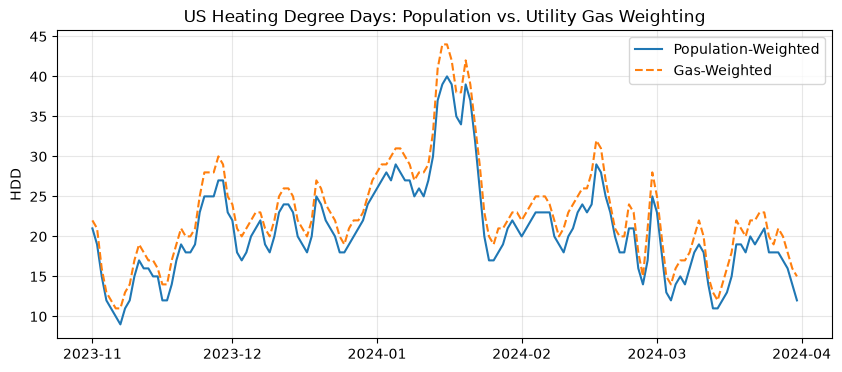

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
from gasp.weather_cpc import fetch_cpc_daily

df_pop = fetch_cpc_daily("Population.Heating.txt", 2023, 2024)
df_gas = fetch_cpc_daily("UtilityGas.Heating.txt", 2023, 2024)
pop_us = df_pop[df_pop["region"] == "US"].set_index("date")["value"]
gas_us = df_gas[df_gas["region"] == "US"].set_index("date")["value"]
winter = pd.DataFrame({"Population-Weighted": pop_us, "Gas-Weighted": gas_us}).loc["2023-11-01":"2024-03-31"]
plt.figure(figsize=(10, 4))
plt.plot(winter.index, winter["Population-Weighted"], label="Population-Weighted")
plt.plot(winter.index, winter["Gas-Weighted"], label="Gas-Weighted", linestyle="--")
plt.title("US Heating Degree Days: Population vs. Utility Gas Weighting")
plt.ylabel("HDD")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The earliest available year was 1981. Yes, all the utility gas files cover the exact same regions. 